<a href="https://colab.research.google.com/github/likhithagcareer/statistics-and-trends/blob/main/life_expectancy_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd

In [16]:
df = pd.read_csv("Life Expectancy Data.csv")

In [17]:
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [18]:
df.shape

(2938, 22)

In [19]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [22]:
print("1. MISSING VALUES")
print(df.isnull().sum())

print("\n2. DUPLICATE RECORDS")
print(df.duplicated().sum())

print("\n3. DESCRIPTIVE STATISTICS")
print(df.describe())

print("\n4. MEAN LIFE EXPECTANCY")
print(df["Life expectancy "].mean())

print("\n5. MEDIAN LIFE EXPECTANCY")
print(df["Life expectancy "].median())

print("\n6. STANDARD DEVIATION")
print(df["Life expectancy "].std())

print("\n7. SKEWNESS")
print(df["Life expectancy "].skew())

print("\n8. KURTOSIS")
print(df["Life expectancy "].kurt())

1. MISSING VALUES
Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
 BMI                                34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
 HIV/AIDS                            0
GDP                                448
Population                         652
 thinness  1-19 years               34
 thinness 5-9 years                 34
Income composition of resources    167
Schooling                          163
dtype: int64

2. DUPLICATE RECORDS
0

3. DESCRIPTIVE STATISTICS
              Year  Life expectancy   Adult Mortality  infan

In [23]:
df.duplicated().sum()

np.int64(0)

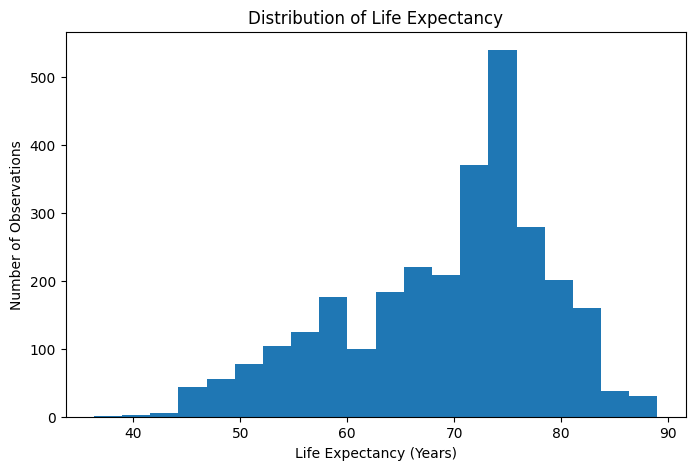

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Life expectancy "].dropna(), bins=20)

plt.title("Distribution of Life Expectancy")
plt.xlabel("Life Expectancy (Years)")
plt.ylabel("Number of Observations")

plt.show()

In [25]:
plt.savefig("life_expectancy_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

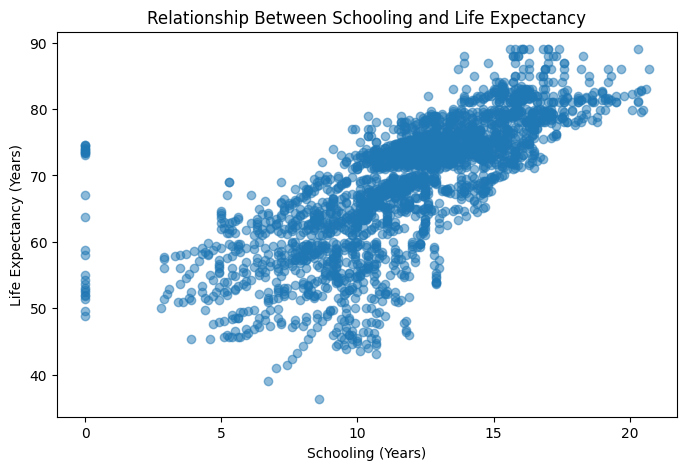

In [26]:
import matplotlib.pyplot as plt

# Remove rows where either variable is missing
plot_data = df[["Schooling", "Life expectancy "]].dropna()

# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    plot_data["Schooling"],
    plot_data["Life expectancy "],
    alpha=0.5
)

plt.title("Relationship Between Schooling and Life Expectancy")
plt.xlabel("Schooling (Years)")
plt.ylabel("Life Expectancy (Years)")

plt.savefig("schooling_vs_life_expectancy.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [29]:
# Remove extra spaces from all column names
df.columns = df.columns.str.strip()

# Display the cleaned column names
print(df.columns.tolist())

['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


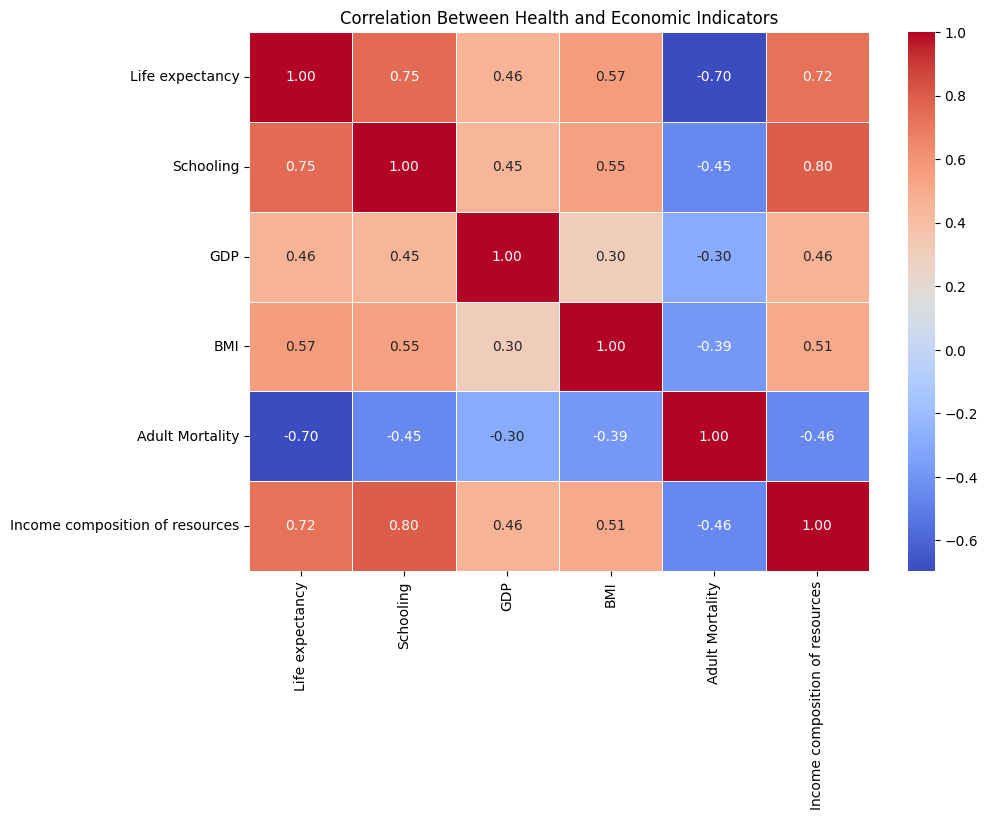

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    "Life expectancy",
    "Schooling",
    "GDP",
    "BMI",
    "Adult Mortality",
    "Income composition of resources"
]

correlation = df[columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Health and Economic Indicators")

plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()